In [2]:
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline

In [26]:
df = pd.read_csv("HR_comma_sep.csv")
df.head(5)

,satisfaction_level,last_evaluation,number_project,average_montly_hours,time_spend_company,Work_accident,left,promotion_last_5years,Department,salary
0,0.38,0.53,2,157,3,0,1,0,sales,low
1,0.80,0.86,5,262,6,0,1,0,sales,medium
2,0.11,0.88,7,272,4,0,1,0,sales,medium
3,0.72,0.87,5,223,5,0,1,0,sales,low
4,0.37,0.52,2,159,3,0,1,0,sales,low


<h2 style="color:purple">Data exploration and visualization</h2>

In [24]:
leftdf = df[df.left==1]
leftdf.shape

(3571, 10)

In [ ]:
num_df = left.drop(['Department','salary'],axis=1)
num_df

In [69]:
num_df.groupby('left').mean()

,satisfaction_level,last_evaluation,number_project,average_montly_hours,time_spend_company,Work_accident,promotion_last_5years
left,,,,,,,
0,0.666810,0.715473,3.786664,199.060203,3.380032,0.175009,0.026251
1,0.440098,0.718113,3.855503,207.419210,3.876505,0.047326,0.005321


From above table we can draw following conclusions,
<ol>
    <li>**Satisfaction Level**: Satisfaction level seems to be relatively low (0.44) in employees leaving the firm vs the retained ones (0.66)</li>
    <li>**Average Monthly Hours**: Average monthly hours are higher in employees leaving the firm (199 vs 207)</li>
    <li>**Promotion Last 5 Years**: Employees who are given promotion are likely to be retained at firm </li>
</ol>

## impact of salary on employees lefting the company

<Axes: xlabel='salary'>

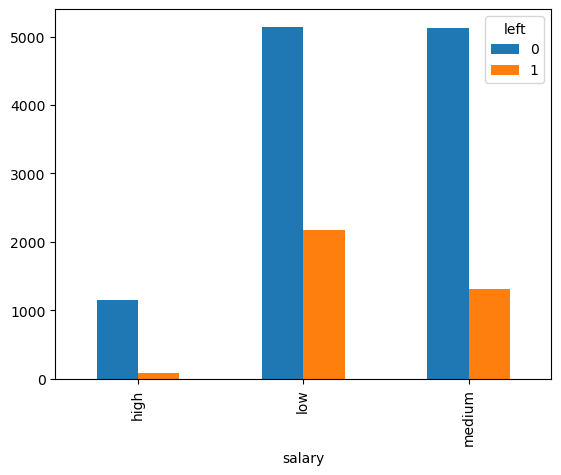

In [82]:
pd.crosstab(df['salary'],df['left']).plot(kind = 'bar')

### from the above table we can see that the more the selary the less probability of employee to left 

In [97]:
dep_eff = df.groupby('Department')['left'].count()
dep_eff

Department
IT             1227
RandD           787
accounting      767
hr              739
management      630
marketing       858
product_mng     902
sales          4140
support        2229
technical      2720
Name: left, dtype: int64

### from the above table we can see that the following departments have the best lefting ration
#### 1- sales
#### 2- support
#### 3- technical

<Axes: xlabel='Department'>

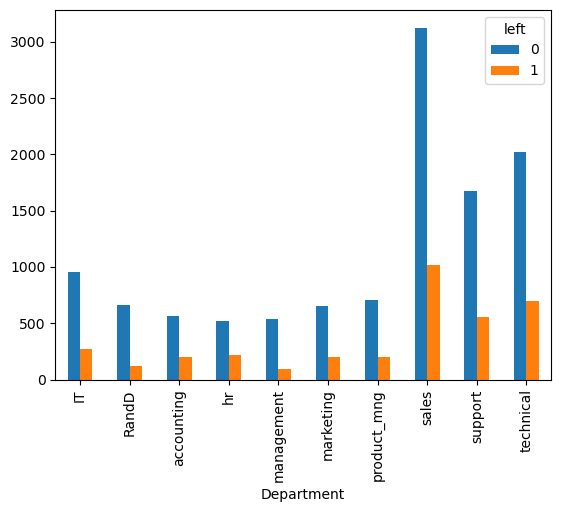

In [93]:
pd.crosstab(df['Department'],df['left']).plot(kind = 'bar')

<h3 style="color:purple">From the data analysis so far we can conclude that we will use following variables as independant variables in our model</h3>
<ol>
    <li>**Satisfaction Level**</li>
    <li>**Average Monthly Hours**</li>
    <li>**Promotion Last 5 Years**</li>
    <li>**Salary**</li>
</ol>

In [98]:
df.head(5)

,satisfaction_level,last_evaluation,number_project,average_montly_hours,time_spend_company,Work_accident,left,promotion_last_5years,Department,salary
0,0.38,0.53,2,157,3,0,1,0,sales,low
1,0.80,0.86,5,262,6,0,1,0,sales,medium
2,0.11,0.88,7,272,4,0,1,0,sales,medium
3,0.72,0.87,5,223,5,0,1,0,sales,low
4,0.37,0.52,2,159,3,0,1,0,sales,low


In [123]:
sub_df= df[['satisfaction_level','average_montly_hours','promotion_last_5years','salary']]
sub_df

,satisfaction_level,average_montly_hours,promotion_last_5years,salary
0,0.38,157,0,low
1,0.80,262,0,medium
2,0.11,272,0,medium
3,0.72,223,0,low
4,0.37,159,0,low
...,...,...,...,...
14994,0.40,151,0,low
14995,0.37,160,0,low
14996,0.37,143,0,low
14997,0.11,280,0,low


In [129]:
dum_df = pd.get_dummies(sub_df['salary'],prefix = 'salary',dtype=int)
dum_df

,salary_high,salary_low,salary_medium
0,0,1,0
1,0,0,1
2,0,0,1
3,0,1,0
4,0,1,0
...,...,...,...
14994,0,1,0
14995,0,1,0
14996,0,1,0
14997,0,1,0


In [163]:
df_with_dummies = pd.concat([sub_df,dum_df],axis='columns')

In [164]:
df_with_dummies.drop(['salary'],axis=1,inplace=True)

In [166]:
X = df_with_dummies.drop('salary_medium',axis=1)

In [170]:
X.head()

,satisfaction_level,average_montly_hours,promotion_last_5years,salary_high,salary_low
0,0.38,157,0,0,1
1,0.80,262,0,0,0
2,0.11,272,0,0,0
3,0.72,223,0,0,1
4,0.37,159,0,0,1


In [168]:
Y = df.left
Y.head()

0    1
1    1
2    1
3    1
4    1
Name: left, dtype: int64

In [186]:
from sklearn.model_selection import  train_test_split
X_train, X_test, y_train, y_test = train_test_split(X,Y,test_size=0.3)

In [187]:
from sklearn.linear_model import  LogisticRegression
model = LogisticRegression()

In [188]:
model.fit(X_train,y_train)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'lbfgs'
,max_iter,100
,multi_class,'deprecated'


In [189]:
model.score(X_test,y_test)

0.7791111111111111

In [190]:
model.score(X_train,y_train)

0.773692732641204

In [194]:
z = model.predict(X_test)


numpy.ndarray

In [195]:
final_predicition=pd.DataFrame(z)

In [196]:
final_predicition.to_csv("humama_solutions.csv")